<a href="https://colab.research.google.com/github/bynak06-cell/Finance-and-Technology/blob/main/Tema_2_Carteras_Intro/src/SP_500_Diversification_Challenge_%E2%80%94_Find_the_Best_Diversifying_Pair.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import missingno as msno


In [2]:
from io import StringIO
import requests

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(url, headers ={"User-Agent": "Mozilla/5.0"}).text

sp500_tickers = pd.read_html(StringIO(html))[0]["Symbol"].to_list()

sp500_tickers = [ticker.replace(".","-") for ticker in sp500_tickers]

start = "2024-01-02"
end = "2025-12-31"

In [3]:
data_raw = yf.download(sp500_tickers,start, end , auto_adjust=True)["Close"]

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
3 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-01-02 -> 2025-12-31) (Yahoo error = "Data doesn\'t exist for startDate = 1704171600, endDate = 1767157200")')


In [4]:
data = data_raw.copy()

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 501 entries, 2024-01-02 to 2025-12-30
Columns: 503 entries, A to ZTS
dtypes: float64(503)
memory usage: 1.9 MB


In [6]:
data.head()

Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,135.917877,183.404007,144.645721,134.479996,103.134529,71.840385,327.203827,580.070007,185.602814,66.223305,...,31.840792,92.002769,57.849808,93.601608,109.875610,72.220001,122.321892,118.228020,267.980011,189.126099
2024-01-03,128.482788,182.030777,145.224976,133.419998,102.824692,73.162132,318.715302,571.789978,181.173187,66.560059,...,31.172670,91.448418,57.950069,94.388008,107.836052,68.629997,122.388268,117.331985,252.520004,185.623901
2024-01-04,128.326050,179.718948,146.130035,133.720001,104.195457,73.666107,317.932434,567.049988,178.402283,65.304039,...,30.742517,91.623482,58.086784,93.565018,108.580338,68.150002,121.999573,117.069008,252.970001,186.691864
2024-01-05,127.895012,178.997742,146.745468,135.979996,104.026459,73.038513,317.489136,564.599976,178.862488,64.448479,...,30.824884,93.023941,58.086784,93.848503,108.406334,66.959999,121.667763,116.854744,252.690002,187.471222
2024-01-08,130.657501,183.324966,146.102875,140.080002,105.528633,73.333298,321.007202,580.549988,181.192352,64.676010,...,31.163517,94.385490,57.950069,92.284821,109.082962,69.309998,121.952171,118.792915,261.089996,188.721985


<Axes: >

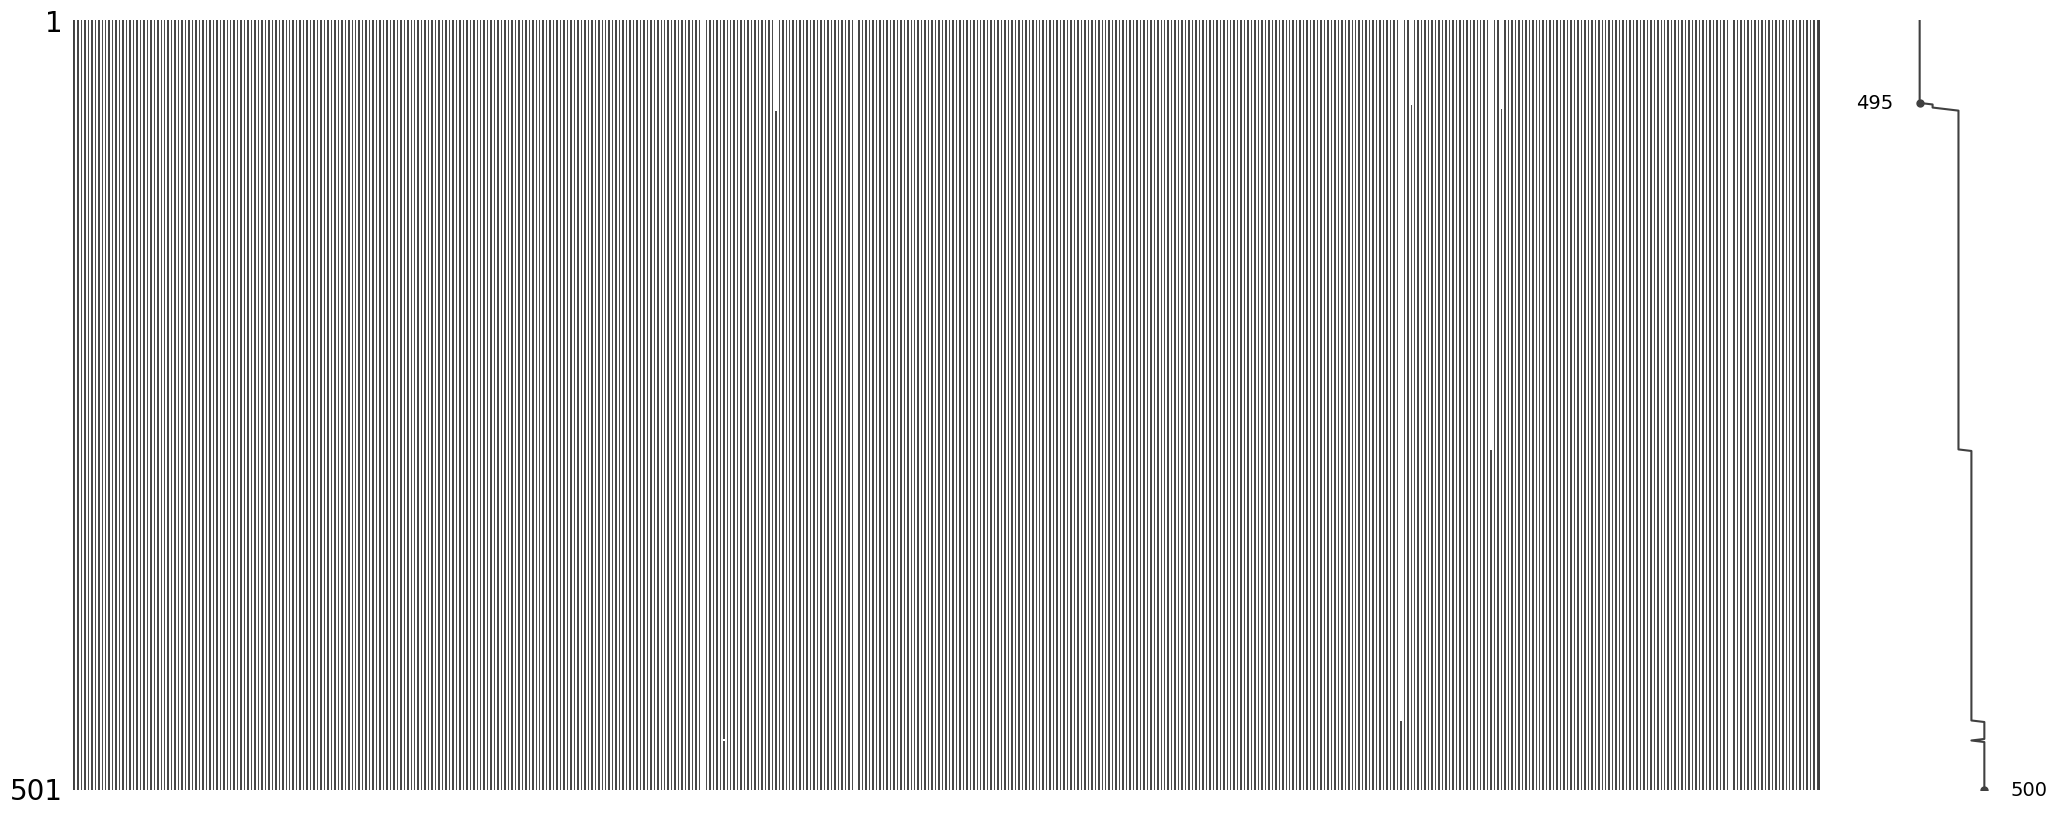

In [7]:
msno.matrix(data)

In [8]:
not_nan = ((data.notna().sum() / data.shape[0]) * 100).sort_values(ascending = False)

In [9]:
not_nan.tail()

,0
Ticker,
SNDK,44.111776
Q,8.982036
HONA,0.000000
FDXF,0.000000
VYLR,0.000000


In [10]:
validos = not_nan[not_nan > 90].index
data = data[validos]
data.shape

(501, 495)

In [11]:
ret = np.log(data).diff().dropna()

<Axes: >

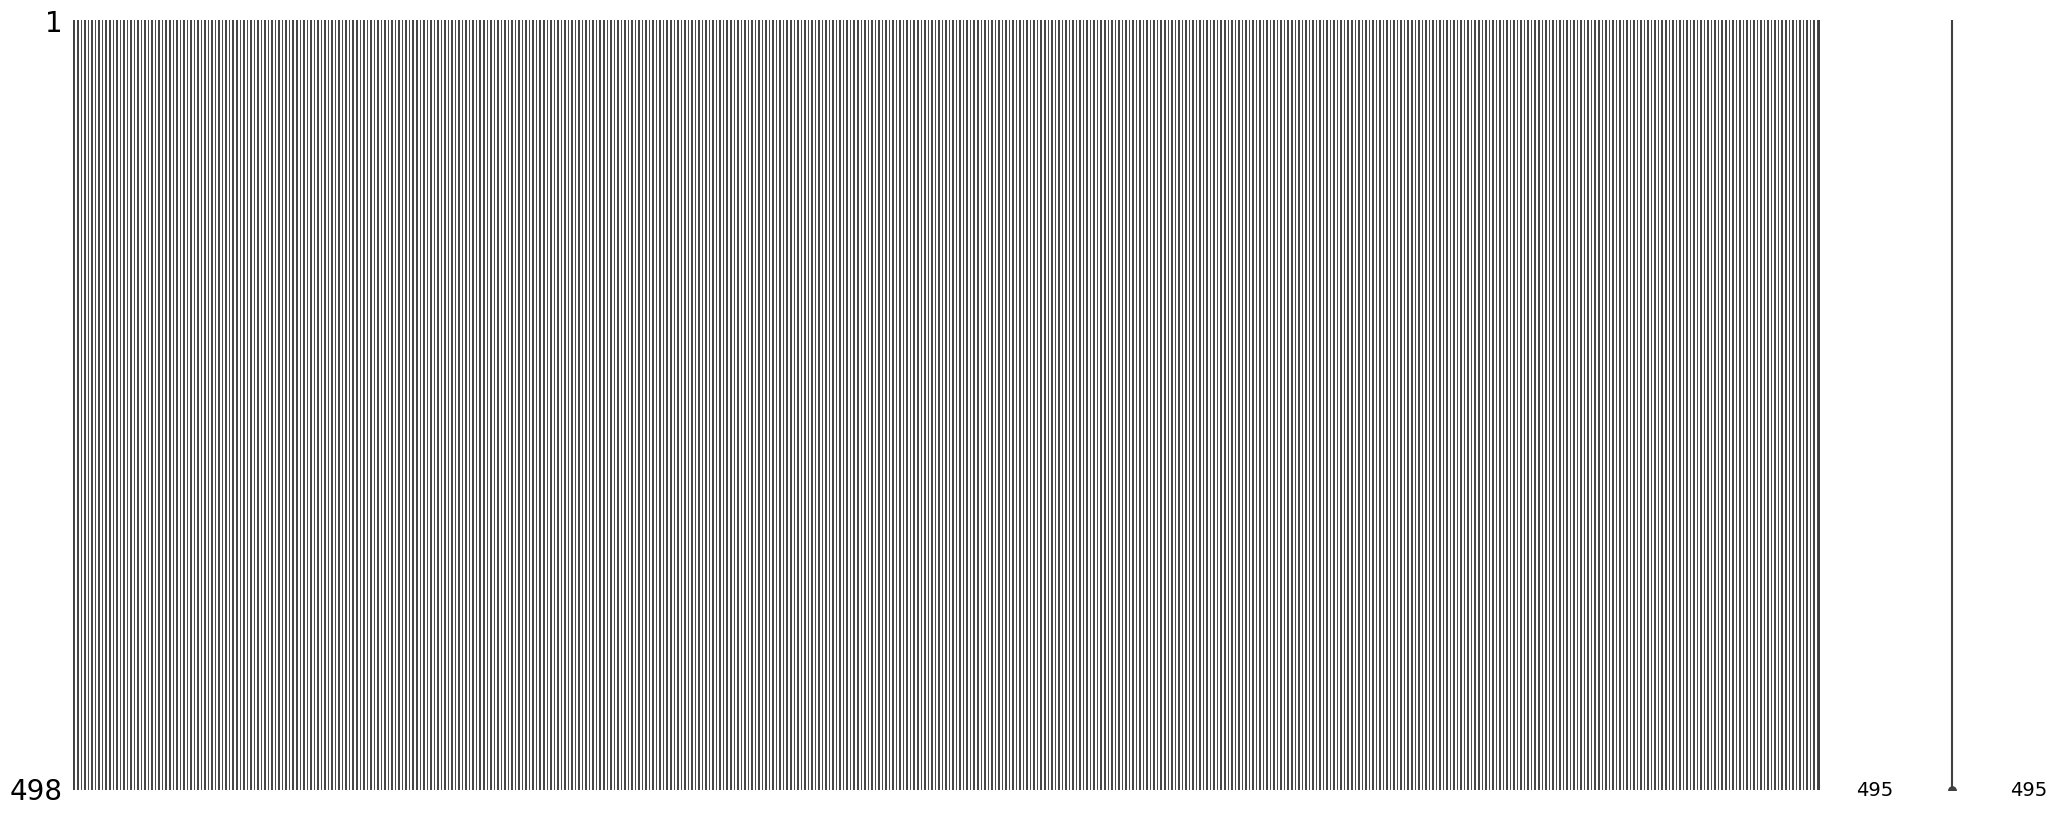

In [12]:
msno.matrix(ret)

In [22]:
vol = ret.rolling(63).std()
mu = ret.mean() * 252

def gain(a,b):
  ret_port = 0.5 * ret[a] + 0.5 * ret[b]
  vol_port = ret_port.rolling(63).std()
  d_gain = 1 - (vol_port / (0.5* vol[a] + 0.5 * vol[b]))
  return d_gain.dropna()

In [27]:
filas = []

for a in range(len(ret.columns)):
    for b in range(a +1,len(ret.columns)):
      i = ret.columns[a]
      j = ret.columns[b]

      d_gain = gain(i,j)
      mean = d_gain.mean()
      std = d_gain.std()
      filas.append({
          "a" : i, "b":j,
          "ret": 0.5 * mu[a] + 0.5 * mu[b],
          "mena": mean, "std":std, "min": d_gain.min(),
          "score":mean - 0.5 * std
      })

/tmp/ipykernel_1113/3440708404.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  "ret": 0.5 * mu[a] + 0.5 * mu[b],


In [28]:
filas

[{'a': 'ZTS',
  'b': 'A',
  'ret': np.float64(-0.10247131707196466),
  'mena': np.float64(0.16511031884926958),
  'std': 0.04554947101699658,
  'min': 0.06063319975272319,
  'score': np.float64(0.1423355833407713)},
 {'a': 'ZTS',
  'b': 'AAPL',
  'ret': np.float64(-0.005896661345568807),
  'mena': np.float64(0.22622308303583122),
  'std': 0.05962497899488349,
  'min': 0.09308030081554064,
  'score': np.float64(0.19641059353838947)},
 {'a': 'ZTS',
  'b': 'ABBV',
  'ret': np.float64(-0.006328225590136585),
  'mena': np.float64(0.19966111031834363),
  'std': 0.06721318407931662,
  'min': 0.0658274289037194,
  'score': np.float64(0.16605451827868534)},
 {'a': 'ZTS',
  'b': 'ABNB',
  'ret': np.float64(-0.10073606475363649),
  'mena': np.float64(0.20744451449398896),
  'std': 0.0675027315651882,
  'min': 0.08521103429125154,
  'score': np.float64(0.17369314871139485)},
 {'a': 'ZTS',
  'b': 'ABT',
  'ret': np.float64(-0.06850085041986766),
  'mena': np.float64(0.18220077057110182),
  'std': 0

In [33]:
df = pd.DataFrame(filas)

In [41]:
A = df.loc[df["score"].idxmax()]

In [42]:
A

,13968
a,AMZN
b,CBOE
ret,0.217021
mena,0.402466
std,0.055872
min,0.250146
score,0.37453


In [43]:
bmark = yf.download("^GSPC",start,end, auto_adjust=True)["Close"]

[*********************100%***********************]  1 of 1 completed


In [45]:
bmark_ret = np.log(bmark).diff().dropna()

In [46]:
bench = bmark_ret.loc[ret.index]

In [48]:
bench_ann = bench.mean() * 252

A AMZN CBOE
  Retorno anual (%): 21.7
  DG medio (%):      40.25
  DG desv. tip. (%): 5.59
  DG mínimo (%):     25.01
  Score (%):         37.45
B AMZN CBOE
  Retorno anual (%): 21.7
  DG medio (%):      40.25
  DG desv. tip. (%): 5.59
  DG mínimo (%):     25.01
  Score (%):         37.45


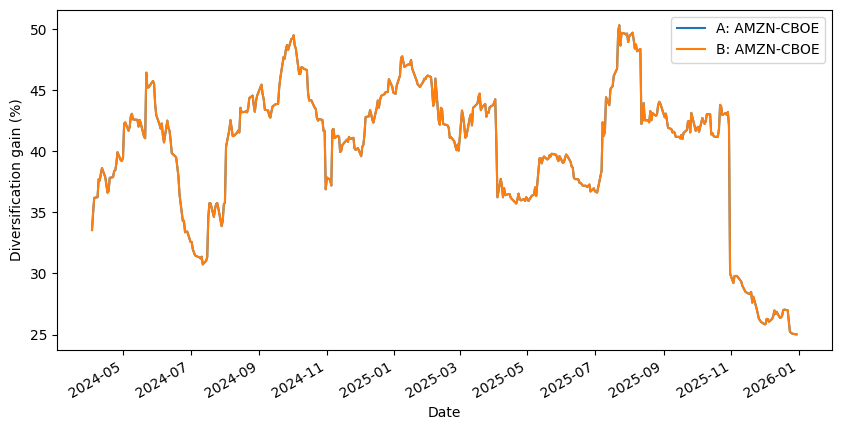

In [55]:
df = df.rename(columns={"mena": "mean"})

bench_ann = float(bench.mean().iloc[0] * 252)   # ajusta si bench ya es una Serie: bench.mean() * 252

A = df.loc[df["score"].idxmax()]
dfB = df[df["ret"] >= bench_ann]
B = dfB.loc[dfB["score"].idxmax()]

for nombre, x in [("A", A), ("B", B)]:
    print(nombre, x["a"], x["b"])
    print("  Retorno anual (%):", round(100 * x["ret"], 2))
    print("  DG medio (%):     ", round(100 * x["mean"], 2))
    print("  DG desv. tip. (%):", round(100 * x["std"], 2))
    print("  DG mínimo (%):    ", round(100 * x["min"], 2))
    print("  Score (%):        ", round(100 * x["score"], 2))

plt.figure(figsize=(10, 5))
(100 * gain(A["a"], A["b"])).plot(label=f"A: {A['a']}-{A['b']}")
(100 * gain(B["a"], B["b"])).plot(label=f"B: {B['a']}-{B['b']}")
plt.ylabel("Diversification gain (%)")
plt.legend()
plt.show()

In [53]:
print(type(bench_ann))

<class 'pandas.core.series.Series'>
